In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mattiuzc/stock-exchange-data/indexData.csv
/kaggle/input/datasets/mattiuzc/stock-exchange-data/indexInfo.csv
/kaggle/input/datasets/mattiuzc/stock-exchange-data/indexProcessed.csv


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load dataset
df = pd.read_csv('/kaggle/input/datasets/mattiuzc/stock-exchange-data/indexData.csv')

# Display dataset
print("First 5 rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,Index,Date,Open,High,Low,Close,Adj Close,Volume
0,NYA,1965-12-31,528.690002,528.690002,528.690002,528.690002,528.690002,0.0
1,NYA,1966-01-03,527.210022,527.210022,527.210022,527.210022,527.210022,0.0
2,NYA,1966-01-04,527.840027,527.840027,527.840027,527.840027,527.840027,0.0
3,NYA,1966-01-05,531.119995,531.119995,531.119995,531.119995,531.119995,0.0
4,NYA,1966-01-06,532.070007,532.070007,532.070007,532.070007,532.070007,0.0



Dataset Shape: (112457, 8)

Column Names:
['Index', 'Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112457 entries, 0 to 112456
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   Index      112457 non-null  object 
 1   Date       112457 non-null  object 
 2   Open       110253 non-null  float64
 3   High       110253 non-null  float64
 4   Low        110253 non-null  float64
 5   Close      110253 non-null  float64
 6   Adj Close  110253 non-null  float64
 7   Volume     110253 non-null  float64
dtypes: float64(6), object(2)
memory usage: 6.9+ MB

Statistical Summary:


,Open,High,Low,Close,Adj Close,Volume
count,110253.000000,110253.000000,110253.000000,110253.000000,110253.000000,1.102530e+05
mean,7658.515222,7704.372961,7608.000422,7657.545872,7657.351729,1.273975e+09
std,9011.478913,9066.638548,8954.506981,9011.510444,9011.608900,4.315783e+09
min,54.869999,54.869999,54.869999,54.869999,54.869999,0.000000e+00
25%,1855.030029,1864.510010,1843.979980,1855.060059,1854.179565,0.000000e+00
50%,5194.089844,5226.279785,5154.049805,5194.750000,5194.750000,4.329000e+05
75%,10134.299810,10207.820310,10060.349610,10134.830080,10134.830080,1.734314e+08
max,68775.062500,69403.750000,68516.992190,68775.062500,68775.062500,9.440374e+10


In [3]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Convert Date column if it exists
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Display dataset information
print("\nCleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values:
Index           0
Date            0
Open         2204
High         2204
Low          2204
Close        2204
Adj Close    2204
Volume       2204
dtype: int64

Duplicate Rows: 0

Cleaned Dataset Shape: (112457, 8)

Missing Values After Cleaning:
Index           0
Date            0
Open         2204
High         2204
Low          2204
Close        2204
Adj Close    2204
Volume       2204
dtype: int64


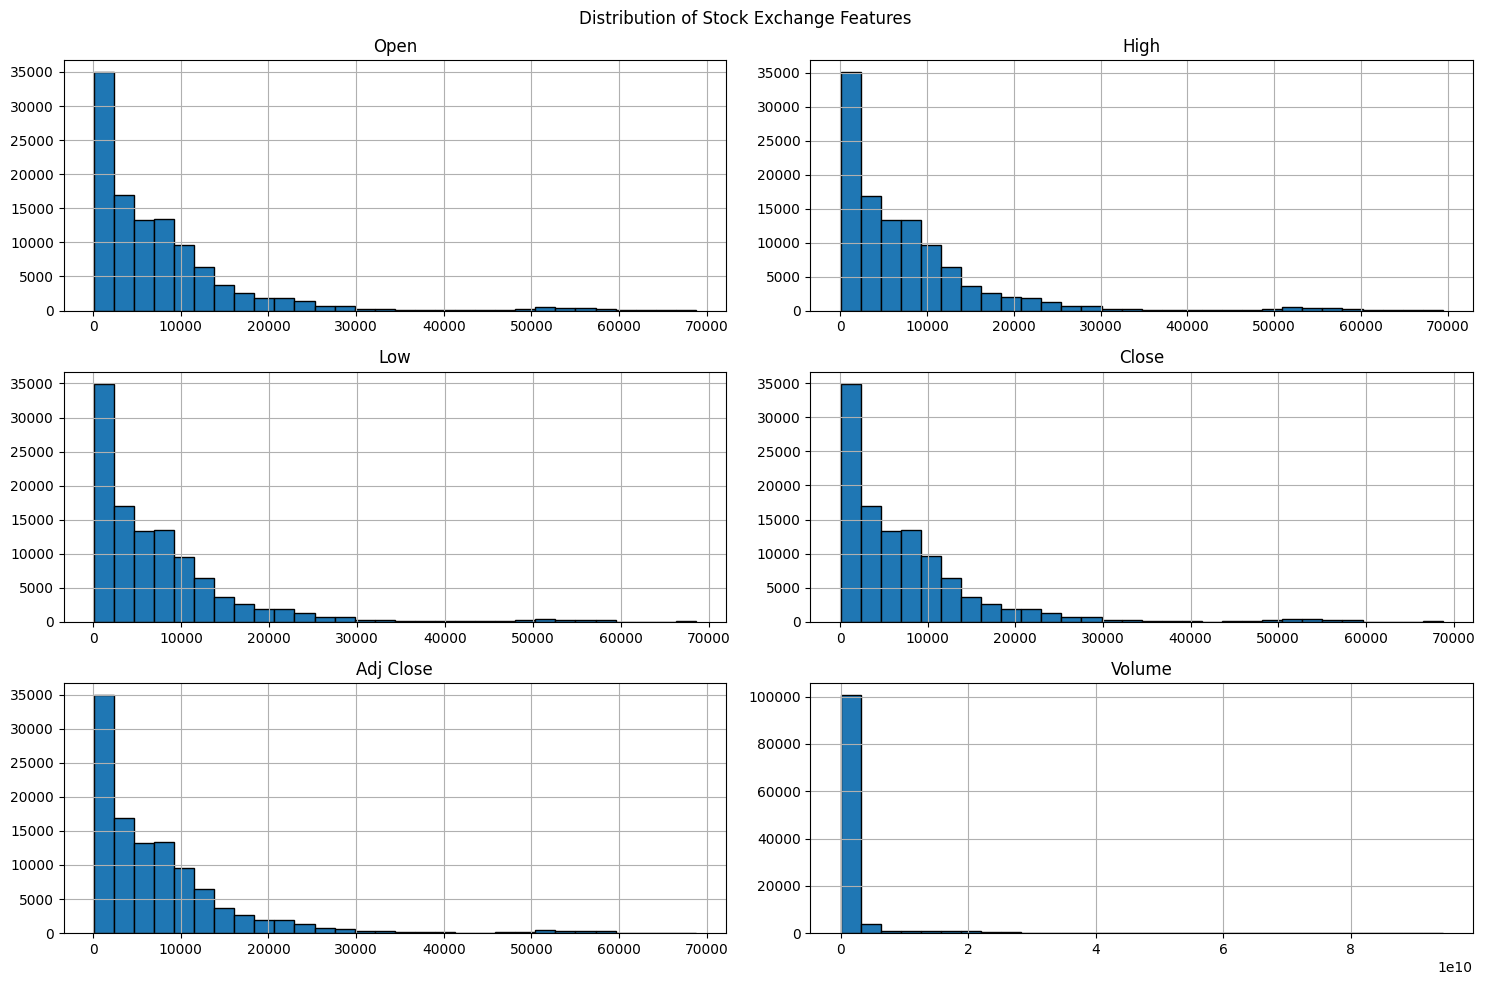

In [4]:
# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Plot distributions
df[numeric_cols].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle("Distribution of Stock Exchange Features")
plt.tight_layout()
plt.show()

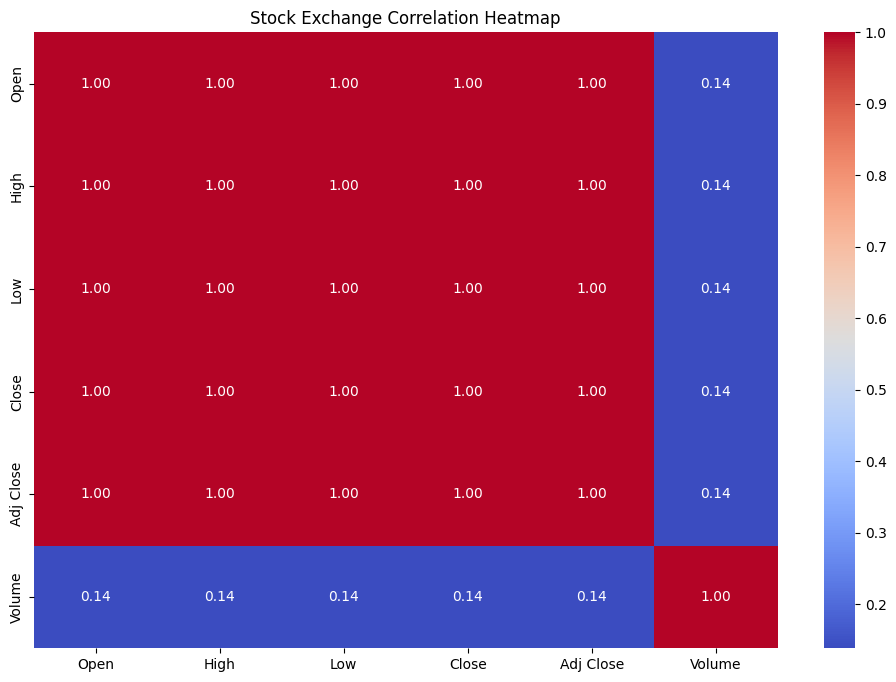

In [5]:
plt.figure(figsize=(12, 8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Stock Exchange Correlation Heatmap")
plt.show()

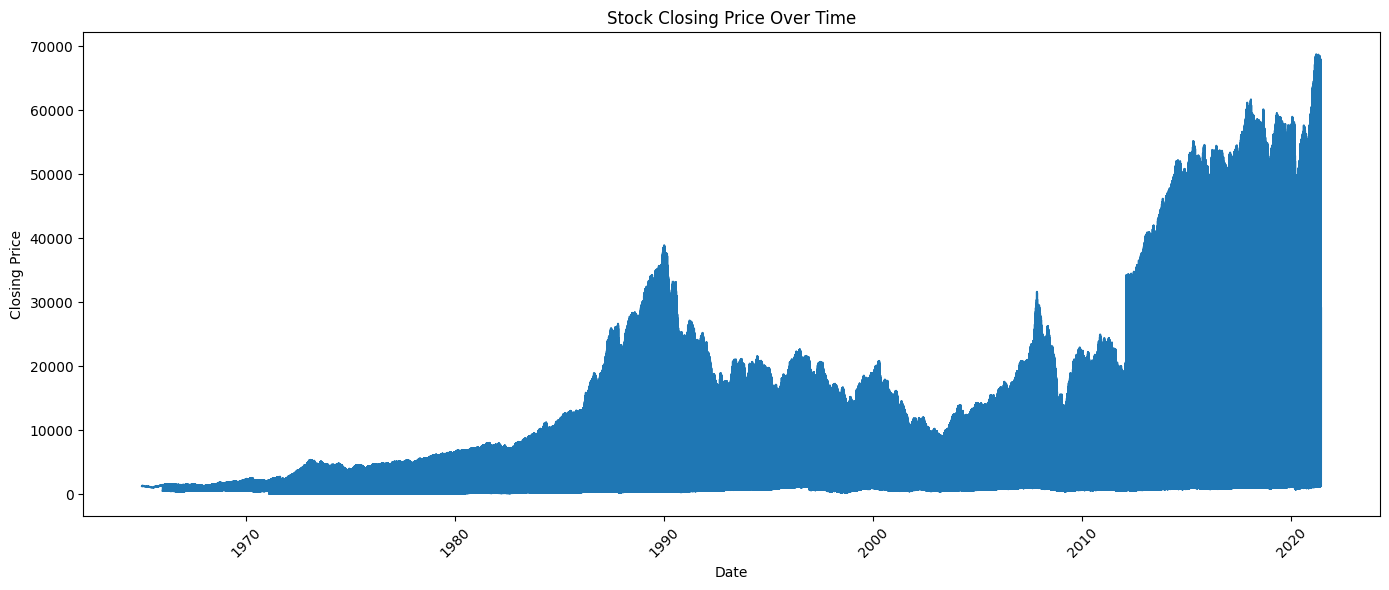

In [6]:
if 'Date' in df.columns and 'Close' in df.columns:

    df_sorted = df.sort_values('Date')

    plt.figure(figsize=(14, 6))

    plt.plot(
        df_sorted['Date'],
        df_sorted['Close']
    )

    plt.title("Stock Closing Price Over Time")
    plt.xlabel("Date")
    plt.ylabel("Closing Price")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("Date or Close column not found.")

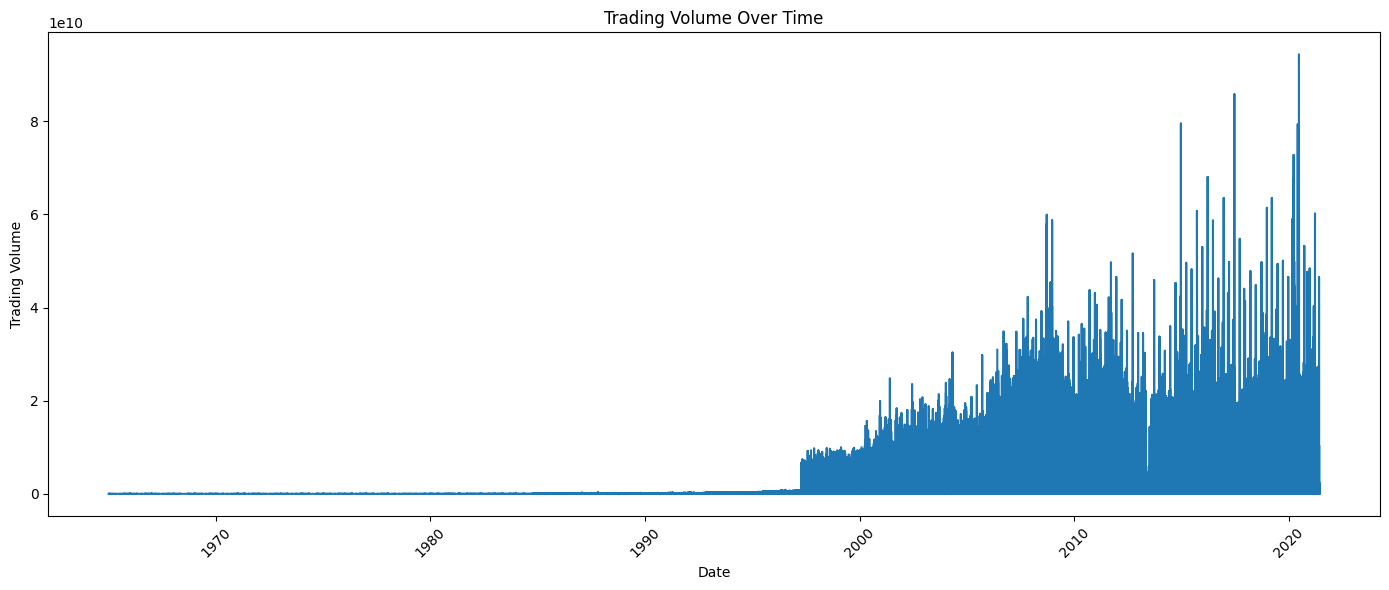

In [7]:
if 'Date' in df.columns and 'Volume' in df.columns:

    df_sorted = df.sort_values('Date')

    plt.figure(figsize=(14, 6))

    plt.plot(
        df_sorted['Date'],
        df_sorted['Volume']
    )

    plt.title("Trading Volume Over Time")
    plt.xlabel("Date")
    plt.ylabel("Trading Volume")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

else:
    print("Date or Volume column not found.")

In [8]:
# Sort data chronologically
df = df.sort_values('Date').copy()

# Convert closing prices to numeric
df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

# Create historical features
df['Previous_Close'] = df['Close'].shift(1)

df['Daily_Return'] = (
    df.groupby('Index')['Close']
      .pct_change(fill_method=None)
)

df['MA_5'] = df['Close'].rolling(window=5).mean()

df['MA_10'] = df['Close'].rolling(window=10).mean()

df['Price_Change'] = df['Close'] - df['Previous_Close']

# Target:
# 1 = next day's closing price is higher
# 0 = next day's closing price is not higher
df['Target'] = (
    df['Close'].shift(-1) > df['Close']
).astype(int)

# Remove rows containing missing feature values
df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=[
        'Previous_Close',
        'Daily_Return',
        'MA_5',
        'MA_10',
        'Price_Change'
    ]
)

# Remove the final row because its next-day target is unknown
df = df.iloc[:-1].copy()

# Define features and target
features = [
    'Previous_Close',
    'Daily_Return',
    'MA_5',
    'MA_10',
    'Price_Change'
]

X = df[features]
y = df['Target']

print("Features:")
display(X.head())

print("\nTarget Distribution:")
print(y.value_counts())

Features:


,Previous_Close,Daily_Return,MA_5,MA_10,Price_Change
92468,1247.199951,-0.003953,1249.089990,1258.863989,-4.929931
92469,1242.270020,0.000451,1247.711987,1255.978980,0.559936
92470,1242.829956,-0.003283,1245.851978,1252.819983,-4.079956
92471,1238.750000,0.007491,1243.815991,1250.734985,9.280029
92472,1248.030029,0.010873,1246.695996,1249.848987,13.569947



Target Distribution:
Target
0    49768
1    48620
Name: count, dtype: int64


In [9]:
# Chronological 80/20 split
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    class_weight='balanced'
)

# Train model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


Model Accuracy: 69.82 %

Classification Report:
              precision    recall  f1-score   support

Price Not Up       0.64      0.91      0.75      9903
    Price Up       0.84      0.49      0.62      9775

    accuracy                           0.70     19678
   macro avg       0.74      0.70      0.68     19678
weighted avg       0.74      0.70      0.68     19678



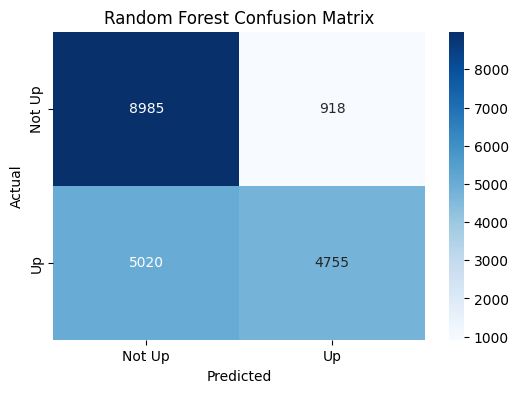

In [10]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Price Not Up', 'Price Up'],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Up', 'Up'],
    yticklabels=['Not Up', 'Up']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

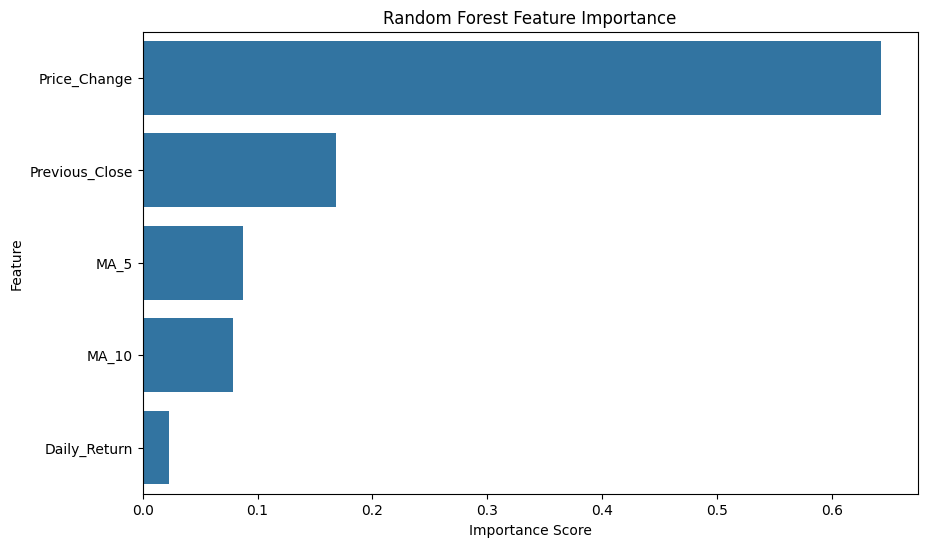

,Feature,Importance
4,Price_Change,0.642537
0,Previous_Close,0.168172
2,MA_5,0.087419
3,MA_10,0.078895
1,Daily_Return,0.022977


In [11]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.show()

display(importance)

In [12]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

results['Actual'] = results['Actual'].map({
    0: 'Not Up',
    1: 'Up'
})

results['Predicted'] = results['Predicted'].map({
    0: 'Not Up',
    1: 'Up'
})

display(results.head(20))

,Actual,Predicted
90963,Not Up,Not Up
110956,Up,Up
68557,Not Up,Not Up
12473,Not Up,Not Up
82582,Not Up,Up
39928,Up,Up
50657,Not Up,Not Up
25163,Up,Up
33942,Not Up,Not Up
59994,Up,Up


In [13]:
latest_data = X.iloc[[-1]]

prediction = rf_model.predict(latest_data)[0]

probabilities = rf_model.predict_proba(latest_data)[0]

print("Predicted Direction:")

if prediction == 1:
    print("Stock price may increase.")
else:
    print("Stock price may not increase.")

print(
    "Probability of price increasing:",
    round(probabilities[list(rf_model.classes_).index(1)] * 100, 2),
    "%"
)

Predicted Direction:
Stock price may not increase.
Probability of price increasing: 49.22 %
